# Power Line Warnings from Wind and Temperature Forecasts

Overhead power lines can carry less current when it is hot and calm, because the conductors are cooled less efficiently. This notebook combines MeteoSwiss OGD forecasts (ICON-CH2-EPS) with the Swiss power line network from OpenStreetMap to produce two warning forecasts along the lines:

| Forecast | Thresholds | Warning levels |
|---|---|---|
| Wind speed | 0.4, 2, 3, 5, 7 m/s | 6 (level 1 = wind ≥ 7 m/s, level 6 = wind ≤ 0.4 m/s) |
| Temperature | 20, 30, 35 °C | 4 (level 1 = T < 20 °C, level 4 = T ≥ 35 °C) |

The compound thresholds are taken from a [presentation](https://doi.org/10.5194/ems2026-764) by I. Schicker from Geosphere Austria.

In [40]:
import copy

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from scipy import sparse
from shapely.affinity import translate
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap
import pandas as pd

import osm_flex.download as dl
import osm_flex.extract as ex
import climada.util.lines_polys_handler as u_lp


from climada import CONFIG
from climada.hazard.forecast import HazardForecast
from climada.engine import ImpactCalc
from climada.entity import LitPop, Exposures, ImpactFunc, ImpactFuncSet
from climada.engine.calibration_opt import init_impf

# define data paths
# path_to_canton_shapes = f"{CONFIG.local_data.data_dir}/ch_shapefile/swissTLMRegio_KANTONSGEBIET_LV95.shp"
# path_to_warningregion_shapes = f"{CONFIG.local_data.data_dir}/ch_shapefile/warning_regions/Warningregions.shp"
gdf_cantons = gpd.read_file(
    "https://github.com/wmgeolab/geoBoundaries/raw/main/releaseData/gbOpen/CHE/ADM1/geoBoundaries-CHE-ADM1.geojson"
).to_crs(epsg=4326)

## 1. Download wind speed and temperature forecasts

We fetch the 10 m wind components (`U_10M`, `V_10M`) and the 2 m temperature (`T_2M`) for all ensemble members and crop them to Switzerland right away to save memory. Wind speed is the norm of the two components; temperature is converted to °C.

In [ ]:
N_DAYS = 0

from earthkit.data import config
from meteodatalab import ogd_api
config.set("cache-policy", "temporary")

lead_times = [f"P0DT{i}H" for i in np.arange(N_DAYS*9, (N_DAYS+1)*9)] # lead times of ICON-CH2-EPS up 5d
lead_times_window = lead_times[0].lstrip("P0DT") + " - " + lead_times[-1].lstrip("P0DT")
model = "ogd-forecasting-icon-ch2"
reftime = "latest"
forecasts = {}
for nwp_var in ["VMAX_10M", "T_2M"]:

    req_det = ogd_api.Request(
        collection=model,
        variable=nwp_var,
        reference_datetime=reftime,
        perturbed=False,  # deterministic forecast
        lead_time=lead_times,
    )
    fct_det =  ogd_api.get_from_ogd(req_det)

    req_pert = ogd_api.Request(
        collection=model,
        variable=nwp_var,
        reference_datetime=reftime,
        perturbed=True,  # perturbed forecasts
        lead_time=lead_times,
    )
    fct_pert =  ogd_api.get_from_ogd(req_pert)

    da_forecast = xr.concat([fct_det, fct_pert], dim="eps")
    forecasts[nwp_var] = da_forecast
    reference_time = str(da_forecast.ref_time.values[0])[:-13]

earthkit-data cache: filesystem usage (96%) exceeds limit (95%) set by 'maximum-cache-disk-usage' config option
earthkit-data cache: trying to free 4.6 GiB
earthkit-data cache: could not free 4.6 GiB
earthkit-data cache: filesystem usage (96%) exceeds limit (95%) set by 'maximum-cache-disk-usage' config option                                                  
earthkit-data cache: trying to free 4.6 GiB
earthkit-data cache: could not free 4.6 GiB
earthkit-data cache: filesystem usage (96%) exceeds limit (95%) set by 'maximum-cache-disk-usage' config option
earthkit-data cache: trying to free 4.6 GiB
earthkit-data cache: could not free 4.6 GiB
earthkit-data cache: filesystem usage (96%) exceeds limit (95%) set by 'maximum-cache-disk-usage' config option                                                  
earthkit-data cache: trying to free 4.6 GiB
earthkit-data cache: could not free 4.6 GiB
earthkit-data cache: filesystem usage (96%) exceeds limit (95%) set by 'maximum-cache-disk-usage' co

## 2. Create the hazard forecasts

`create_hazard_forecast` reduces the hourly data to one value per forecast day and ensemble member. It takes the daily maximum, which is what we want for temperature. For wind we aggregate to the **daily mean** beforehand (use `"min"` for a worst-case view).

In [42]:
# create HazardForecast object from downloaded dataarray
haz_fc_wind = HazardForecast.from_xarray_raster(
    forecasts["VMAX_10M"].to_dataset(name="VMAX_10M"),
    hazard_type="WS",
    intensity_unit="m/s",
    coordinate_vars={
        "longitude": "lon",
        "latitude": "lat",
        "lead_time": "lead_time",
        "member": "eps",
    },
    intensity="VMAX_10M",
)
haz_fc_temp = HazardForecast.from_xarray_raster(
    forecasts["T_2M"].to_dataset(name="T_2M"),
    hazard_type="TEMP",
    intensity_unit="°C",
    coordinate_vars={
        "longitude": "lon",
        "latitude": "lat",
        "lead_time": "lead_time",
        "member": "eps",
    },
    intensity="T_2M",
)

haz_fc_temp.intensity = sparse.csr_matrix(haz_fc_temp.intensity.toarray() - 273.15)


2026-10-19 18:28:57,329 - climada.hazard.xarray - WARNING - Failed to read values of 'event' as dates. Hazard.event_name will be empty strings
2026-10-19 18:28:57,337 - climada.hazard.xarray - WARNING - Failed to read values of 'event' as dates or ordinals. Hazard.date will be ones only
2026-10-19 18:29:07,475 - climada.hazard.xarray - WARNING - Failed to read values of 'event' as dates. Hazard.event_name will be empty strings
2026-10-19 18:29:07,480 - climada.hazard.xarray - WARNING - Failed to read values of 'event' as dates or ordinals. Hazard.date will be ones only


## 3. Power line exposure from OpenStreetMap

We download the Swiss OSM extract from Geofabrik (~500 MB, stored in `~/osm`) and extract all features tagged `power=line`. This takes a few minutes the first time.

In [ ]:
# # to download the data
# path_che_dump = dl.get_country_geofabrik("CHE")
# gdf_power = ex.extract_cis(path_che_dump, "power")
# power_lines = gdf_power.loc[gdf_power["power"] == "line"]
# exp_lines = Exposures(power_lines[["osm_id", "voltage", "geometry"]])


# to read existing data
# exp_lines = Exposures.from_hdf5("exp_powerlines_CHE.h5")
exp_lines = Exposures.from_hdf5("/home/renku/work/gebhart-renku/exp_powerlines_CHE.h5")


extract lines: 100%|██████████| 12707/12707 [00:26<00:00, 487.30it/s] 


The lines become a CLIMADA `Exposures` object with value 1, so that the computed "impact" equals the warning level. Each line is split into points every 500 m, and each point is matched to its nearest forecast grid cell.

2026-10-19 18:33:34,581 - climada.util.lines_polys_handler - WARNING - 578 lines with a length < 10*resolution were found. Each of these lines is disaggregate to one point. Reaggregatint values will thus likely lead to overestimattion. Consider chosing a smaller resolution or filter out the short lines. 
5446 power lines, 10400 km, 23796 points


<Axes: >

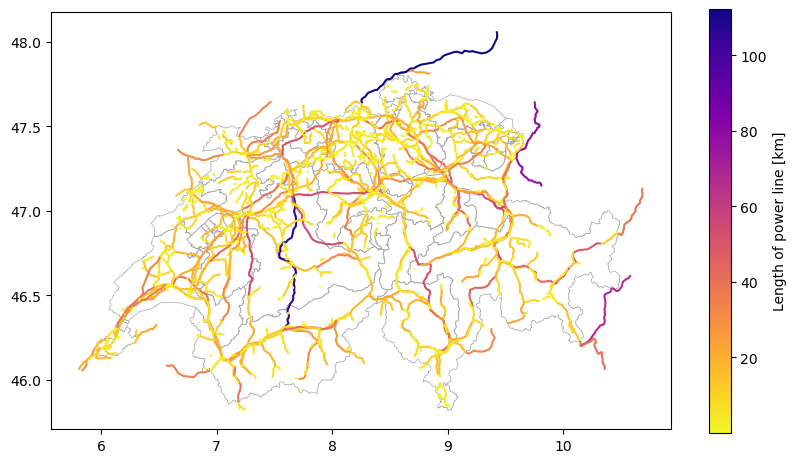

In [ ]:
exp_lines.gdf["value"] = 1
exp_lines.gdf["length_km"] = exp_lines.gdf.geometry.to_crs(epsg=2056).length / 1000

exp_points = u_lp.exp_geom_to_pnt(
    exp_lines, res=500, to_meters=True, disagg_met=u_lp.DisaggMethod.FIX, disagg_val=1)
exp_points.gdf["impf_WS"] = 1
exp_points.gdf["impf_TEMP"] = 1
exp_points.assign_centroids(haz_fc_wind, threshold=5)
exp_points.assign_centroids(haz_fc_temp, threshold=5)

print(f"{len(exp_lines.gdf)} power lines, {exp_lines.gdf.length_km.sum():.0f} km, {len(exp_points.gdf)} points")
ax = exp_lines.gdf.plot("length_km", cmap="plasma_r", legend=True, legend_kwds={"label": "Length of power line [km]"}, figsize=(10,5.5))
gdf_cantons.boundary.plot(ax=ax, color="darkgray", linewidth=0.5, zorder=0)


## 4. Warning thresholds as impact functions

As in the wind tutorial, the warning levels are encoded as step functions: the mean damage ratio of the impact function is the warning level.

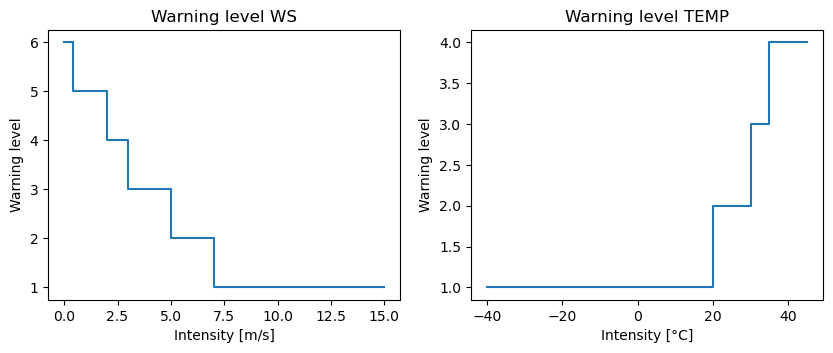

In [45]:
WIND_THRESHOLDS = [0.4, 2, 3, 5, 7]  # m/s
TEMP_THRESHOLDS = [20, 30, 35]  # °C


def warning_impact_function(haz_type, thresholds, levels, intensity_unit, intensity_range):
    thresholds = np.asarray(thresholds, dtype=float)
    impf = ImpactFunc(haz_type=haz_type, id=1, name=f"Warning level {haz_type}", intensity_unit=intensity_unit)
    impf.intensity = np.sort(np.concatenate([intensity_range[:1], thresholds - 1e-9, thresholds, intensity_range[1:]]))
    impf.mdd = np.repeat(levels, 2).astype(float)
    impf.paa = np.ones_like(impf.mdd)
    impf.check()
    return impf


# low wind and high temperature are critical
impf_wind = warning_impact_function("WS", WIND_THRESHOLDS, [6, 5, 4, 3, 2, 1], "m/s", [0, 15])
impf_temp = warning_impact_function("TEMP", TEMP_THRESHOLDS, [1, 2, 3, 4], "°C", [-40, 45])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, impf in zip(axes, [impf_wind, impf_temp]):
    ax.plot(impf.intensity, impf.mdd)
    ax.set(title=impf.name, xlabel=f"Intensity [{impf.intensity_unit}]", ylabel="Warning level")

## 5. Impact-based forecasts

One warning level per line point, ensemble member and forecast day.

In [46]:
imp_wind = ImpactCalc(exp_points, ImpactFuncSet([impf_wind]), haz_fc_wind).impact(assign_centroids=False)
imp_temp = ImpactCalc(exp_points, ImpactFuncSet([impf_temp]), haz_fc_temp).impact(assign_centroids=False)

2026-10-19 18:33:36,492 - climada.hazard.base - WARNING - Impact function id=1 has mdr(0) != 0.The mean damage ratio must thus be computed for all values ofhazard intensity including 0 which can be very time consuming.
2026-10-19 18:33:37,717 - climada.engine.impact_calc - WARNING - eai_exp and aai_agg are undefined with forecasts. Setting them to NaN arrays.
2026-10-19 18:33:38,331 - climada.hazard.base - WARNING - Impact function id=1 has mdr(0) != 0.The mean damage ratio must thus be computed for all values ofhazard intensity including 0 which can be very time consuming.
2026-10-19 18:33:39,531 - climada.engine.impact_calc - WARNING - eai_exp and aai_agg are undefined with forecasts. Setting them to NaN arrays.


For plotting we take the ensemble median per point and show each line with the highest level found along it.

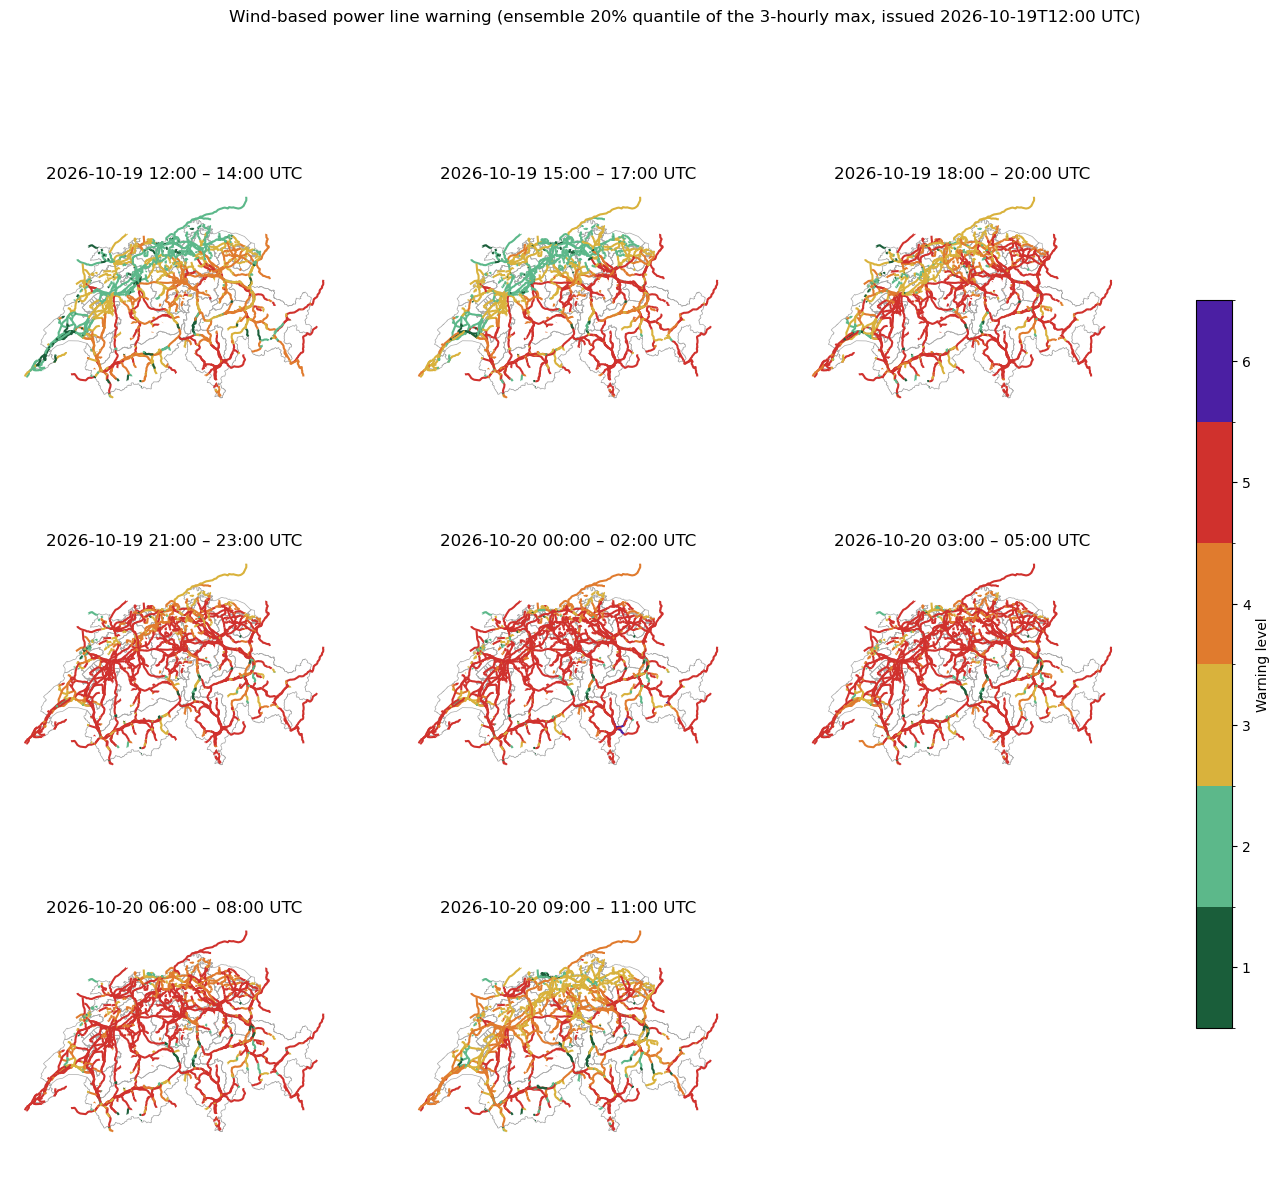

In [47]:
def plot_warning_levels(imp, colors, title, quantile=0.2, group_size=3, ncols=3):
    """Plot the ensemble quantile of the max warning level over groups of consecutive lead times."""
    lead_times = np.unique(imp.lead_time)
    lead_time_groups = [lead_times[i:i + group_size] for i in range(0, len(lead_times), group_size)]
    n_levels = len(colors)
    cmap, norm = ListedColormap(colors), BoundaryNorm(np.arange(0.5, n_levels + 1), n_levels)
    nrows = int(np.ceil(len(lead_time_groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows), squeeze=False)
    axes = axes.flatten()
    for ax in axes:
        ax.set_axis_off()
    imp_mat = imp.imp_mat.toarray()
    for ax, group in zip(axes, lead_time_groups):
        # max over the lead times of the group for each member, then quantile over the members
        in_group = np.isin(imp.lead_time, group)
        member_max = pd.DataFrame(imp_mat[in_group]).groupby(imp.member[in_group]).max()
        levels = np.quantile(member_max.to_numpy(), quantile, axis=0)
        levels = pd.Series(levels, index=exp_points.gdf.index).groupby(level=0).max()
        gdf_cantons.boundary.plot(ax=ax, color="darkgray", linewidth=0.5, zorder=0)
        exp_lines.gdf.assign(level=levels).plot("level", cmap=cmap, norm=norm, linewidth=1.5, ax=ax)
        valid_from = pd.Timestamp(reference_time) + pd.Timedelta(group[0])
        valid_to = pd.Timestamp(reference_time) + pd.Timedelta(group[-1])
        ax.set_title(f"{valid_from:%Y-%m-%d %H:%M} – {valid_to:%H:%M} UTC")
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, ticks=range(1, n_levels + 1),
                 label="Warning level", shrink=0.7)
    fig.suptitle(f"{title} (ensemble {quantile:.0%} quantile of the {group_size}-hourly max, "
                 f"issued {reference_time} UTC)")


WIND_COLORS = ["#1a5e3a", "#5cb88a", "#d9b23c", "#e07b2e", "#d0312d", "#4b1fa3"]
TEMP_COLORS = ["#5cb88a", "#d9b23c", "#e07b2e", "#d0312d"]

plot_warning_levels(imp_wind, WIND_COLORS, "Wind-based power line warning")

In [56]:
# plot_warning_levels(imp_temp, TEMP_COLORS, "Temperature-based power line warning")

## 6. Compound warning level

Finally, we combine the two warning levels into the six compound classes defined above. A degraded class (4–6) needs low wind **and** elevated temperature together, a favorable class (1–2) needs strong wind **and** low temperature; everything else is moderate (3).

| Compound level | Wind | Temperature | Wind level | Temperature level |
|---|---|---|---|---|
| 1 Very favorable | ≥ 7 m/s | < 20 °C | 1 | 1 |
| 2 Favorable | ≥ 5 m/s | < 30 °C | ≤ 2 | ≤ 2 |
| 3 Moderate | default | | | |
| 4 Unfavorable | < 3 m/s | > 20 °C | ≥ 4 | ≥ 2 |
| 5 Critical | < 2 m/s | > 35 °C | ≥ 5 | 4 |
| 6 Super-critical | ≤ 0.4 m/s | > 35 °C | 6 | 4 |

In [49]:
def compound_warning_level(wind_level, temp_level):
    """Combine wind (1-6) and temperature (1-4) warning levels into the compound level (1-6)."""
    wind_level, temp_level = np.asarray(wind_level), np.asarray(temp_level)
    conditions = [
        (wind_level == 6) & (temp_level == 4),  # 6 super-critical
        (wind_level >= 5) & (temp_level == 4),  # 5 critical
        (wind_level >= 4) & (temp_level >= 2),  # 4 unfavorable
        (wind_level == 1) & (temp_level == 1),  # 1 very favorable
        (wind_level <= 2) & (temp_level <= 2),  # 2 favorable
    ]
    return np.select(conditions, [6, 5, 4, 1, 2], default=3)


# compound level for every combination of wind level (rows) and temperature level (columns)
pd.DataFrame(
    compound_warning_level(*np.meshgrid(range(1, 7), range(1, 5), indexing="ij")),
    index=pd.Index(range(1, 7), name="wind level"),
    columns=pd.Index(range(1, 5), name="temperature level"))

temperature level,1,2,3,4
wind level,,,,
1,1,2,3,3
2,2,2,3,3
3,3,3,3,3
4,3,4,4,4
5,3,4,4,5
6,3,4,4,6


Both forecasts share the same points, members and forecast days, so the function can be applied directly to the two impact matrices.

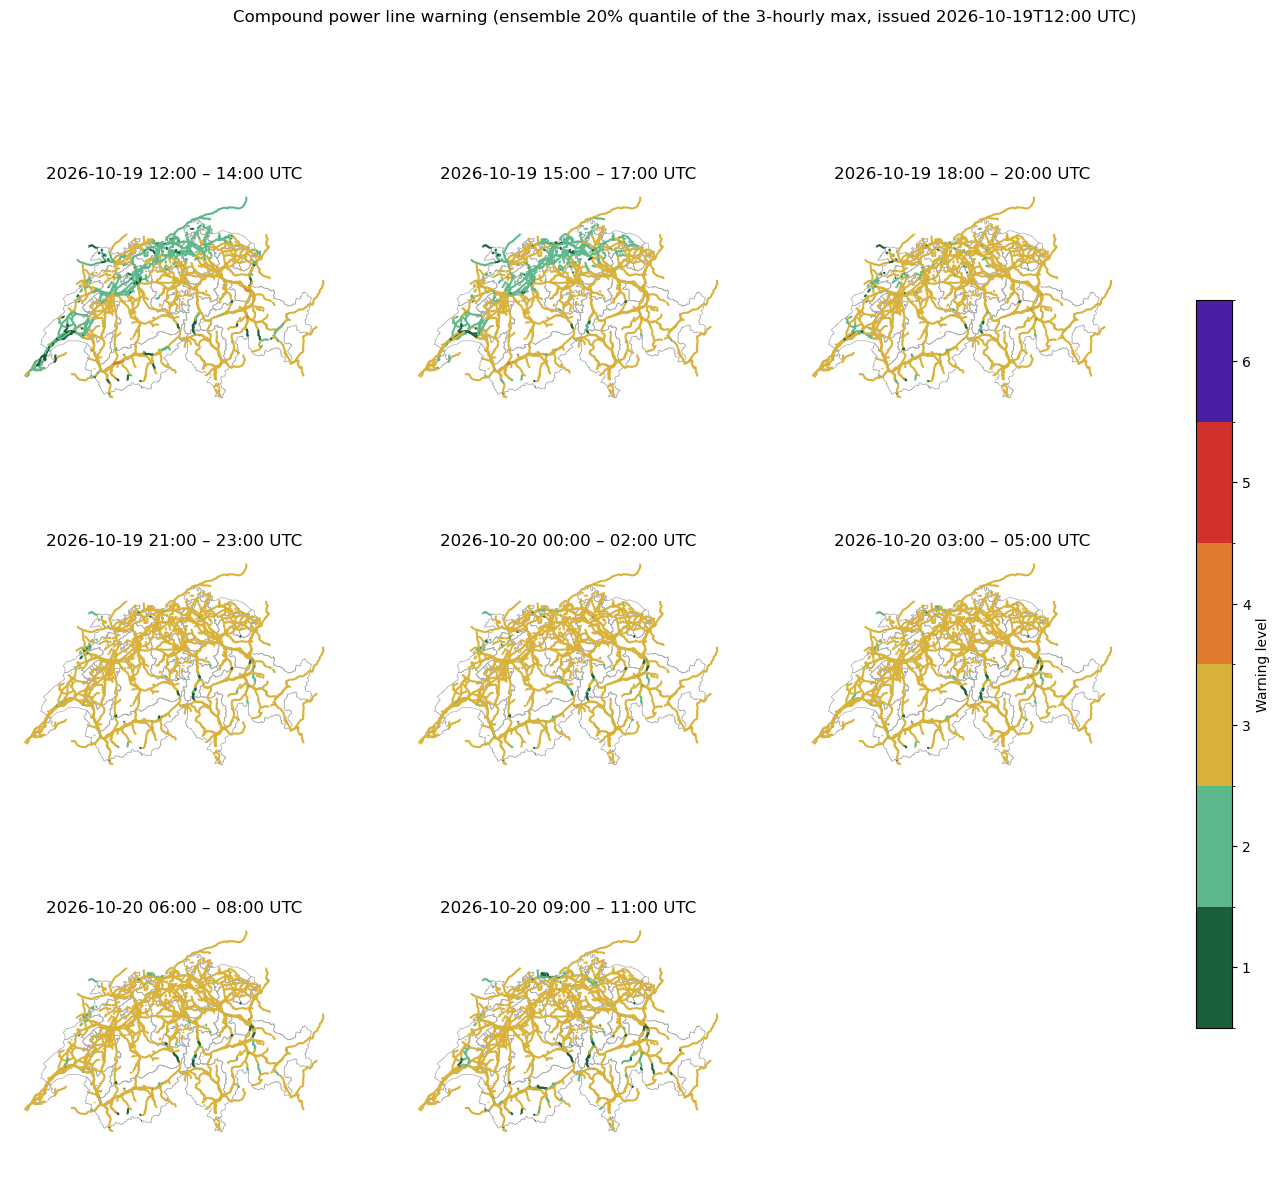

In [50]:
imp_compound = copy.deepcopy(imp_wind)
imp_compound.imp_mat = sparse.csr_matrix(
    compound_warning_level(imp_wind.imp_mat.toarray(), imp_temp.imp_mat.toarray()).astype(float))

plot_warning_levels(imp_compound, WIND_COLORS, "Compound power line warning")

## 7. Further analysis

The maps above show one aggregated level per line. The following plots use the full ensemble and the line lengths to summarise the forecast in other ways. All of them are based on the compound level unless stated otherwise.

First, some shared helpers: the line length each point stands for (each line is split into equal pieces), and the ensemble mean of the line length that falls into a given category at each lead time.

In [51]:
wind_mat = imp_wind.imp_mat.toarray()
temp_mat = imp_temp.imp_mat.toarray()
compound_mat = imp_compound.imp_mat.toarray()

# length of line [km] represented by each point
line_id = exp_points.gdf.index.get_level_values(0)
point_km = exp_lines.gdf.length_km.loc[line_id].to_numpy() / line_id.map(line_id.value_counts()).to_numpy()


def ensemble_mean_km(imp, categories):
    """Ensemble mean of the line length [km] in each category per lead time.

    categories maps a name to a boolean matrix (events x points)."""
    km = pd.DataFrame({name: mask @ point_km for name, mask in categories.items()})
    km = km.groupby(imp.lead_time).mean()
    km.index = pd.Timestamp(reference_time) + pd.to_timedelta(km.index)
    return km

### 7.1 Probability of an unfavorable compound level

Instead of a single ensemble quantile, these maps show the share of ensemble members in which a line reaches compound level 4 or higher at any point, using the same 3-hour groups of lead times as above.

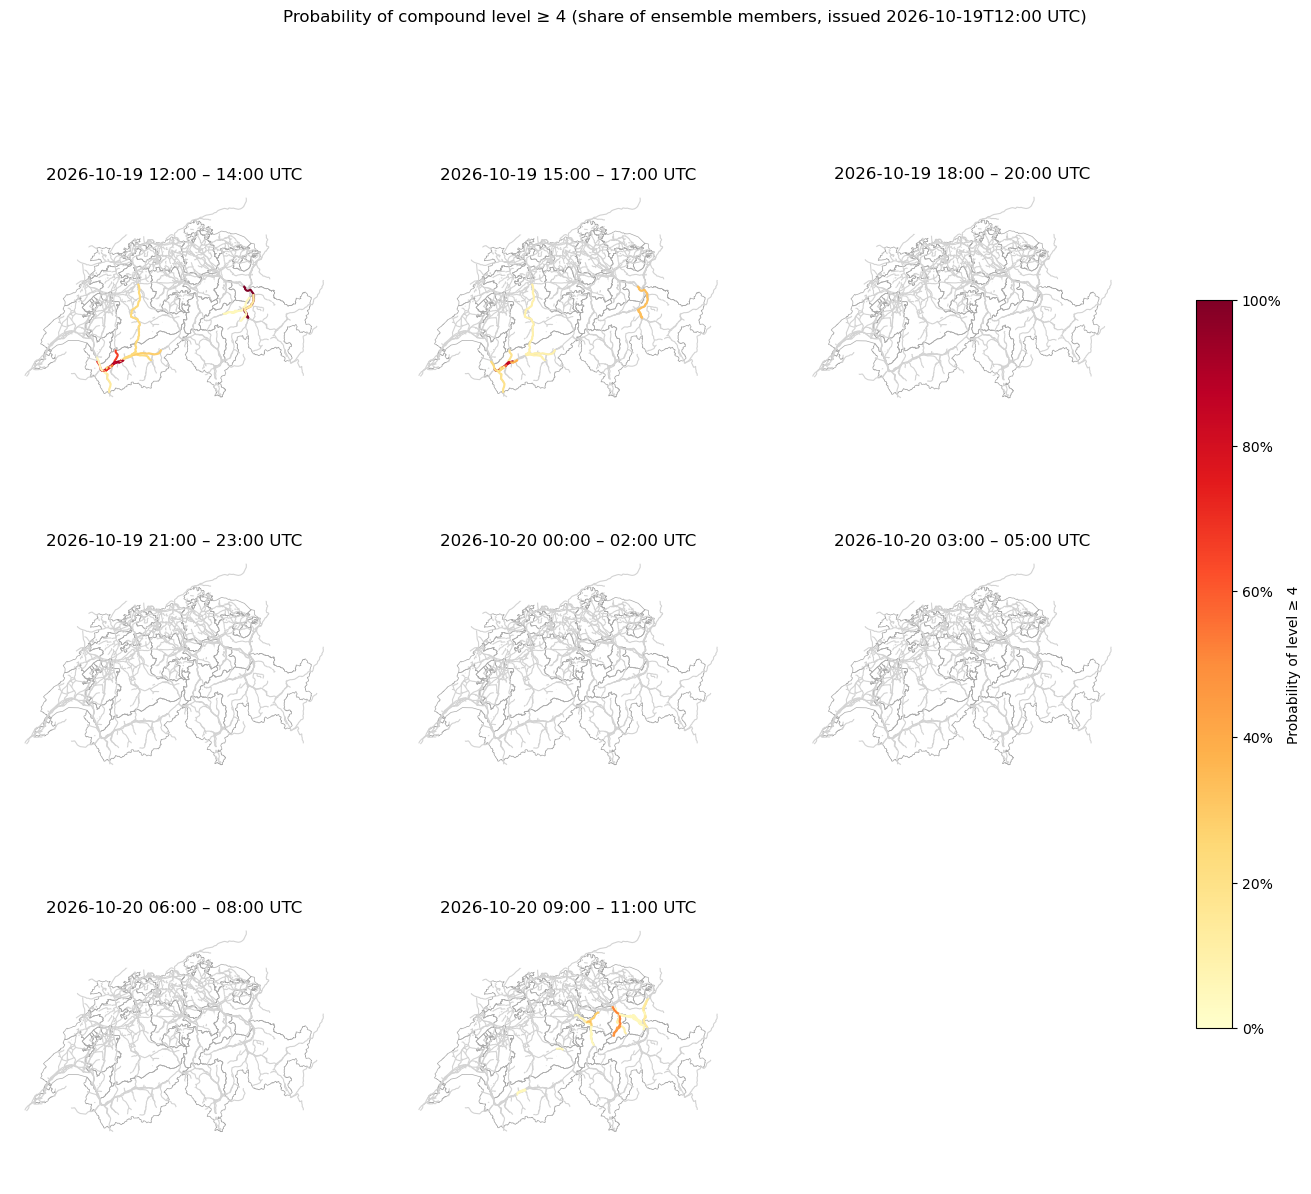

In [52]:
def plot_exceedance_probability(imp, min_level=4, group_size=3, ncols=3):
    """Map the share of members reaching min_level on each line within groups of consecutive lead times."""
    lead_times = np.unique(imp.lead_time)
    lead_time_groups = [lead_times[i:i + group_size] for i in range(0, len(lead_times), group_size)]
    nrows = int(np.ceil(len(lead_time_groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows), squeeze=False)
    axes = axes.flatten()
    for ax in axes:
        ax.set_axis_off()
    imp_mat = imp.imp_mat.toarray()
    for ax, group in zip(axes, lead_time_groups):
        # max over the lead times of the group and over the points of each line, per member
        in_group = np.isin(imp.lead_time, group)
        member_max = pd.DataFrame(imp_mat[in_group]).groupby(imp.member[in_group]).max()
        line_max = member_max.T.set_axis(exp_points.gdf.index).groupby(level=0).max()
        probability = (line_max >= min_level).mean(axis=1)
        gdf_cantons.boundary.plot(ax=ax, color="darkgray", linewidth=0.5, zorder=0)
        lines = exp_lines.gdf.assign(probability=probability)
        lines.plot(color="lightgray", linewidth=0.8, ax=ax)
        if (lines.probability > 0).any():
            lines[lines.probability > 0].plot("probability", cmap="YlOrRd", vmin=0, vmax=1, linewidth=1.5, ax=ax)
        valid_from = pd.Timestamp(reference_time) + pd.Timedelta(group[0])
        valid_to = pd.Timestamp(reference_time) + pd.Timedelta(group[-1])
        ax.set_title(f"{valid_from:%Y-%m-%d %H:%M} – {valid_to:%H:%M} UTC")
    fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap="YlOrRd"), ax=axes,
                 label=f"Probability of level ≥ {min_level}", shrink=0.7, format=ticker.PercentFormatter(1))
    fig.suptitle(f"Probability of compound level ≥ {min_level} (share of ensemble members, issued {reference_time} UTC)")


plot_exceedance_probability(imp_compound, min_level=4)

### 7.2 Line length per warning level over time

Ensemble mean of the kilometres of power line at each warning level for every lead time. The stacks always add up to the full network length.

Text(0.5, 0.98, 'Power line length per warning level (ensemble mean, issued 2026-10-19T12:00 UTC)')

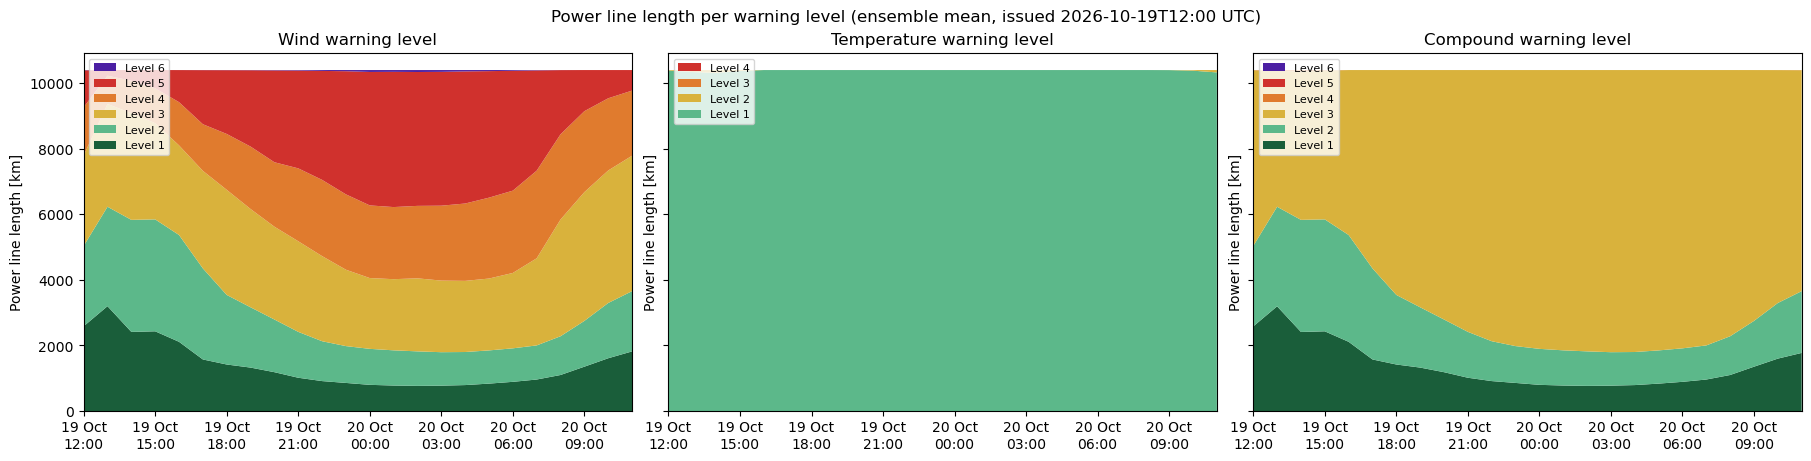

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True, layout="constrained")
for ax, (name, imp, level_mat, colors) in zip(axes, [
    ("Wind", imp_wind, wind_mat, WIND_COLORS),
    ("Temperature", imp_temp, temp_mat, TEMP_COLORS),
    ("Compound", imp_compound, compound_mat, WIND_COLORS),
]):
    levels = range(1, len(colors) + 1)
    km = ensemble_mean_km(imp, {level: level_mat == level for level in levels})
    ax.stackplot(km.index, km.T.to_numpy(), labels=[f"Level {level}" for level in levels], colors=colors)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="upper left", fontsize=8)
    ax.set(title=f"{name} warning level", ylabel="Power line length [km]", xlim=(km.index[0], km.index[-1]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
fig.suptitle(f"Power line length per warning level (ensemble mean, issued {reference_time} UTC)")

### 7.3 Is it the wind or the heat?

An unfavorable compound level (≥ 4) needs both calm wind (wind level ≥ 4, < 3 m/s) and warm air (temperature level ≥ 2, > 20 °C). This plot shows how much of the network meets both conditions, and how much meets only one of them and is therefore not (yet) flagged.

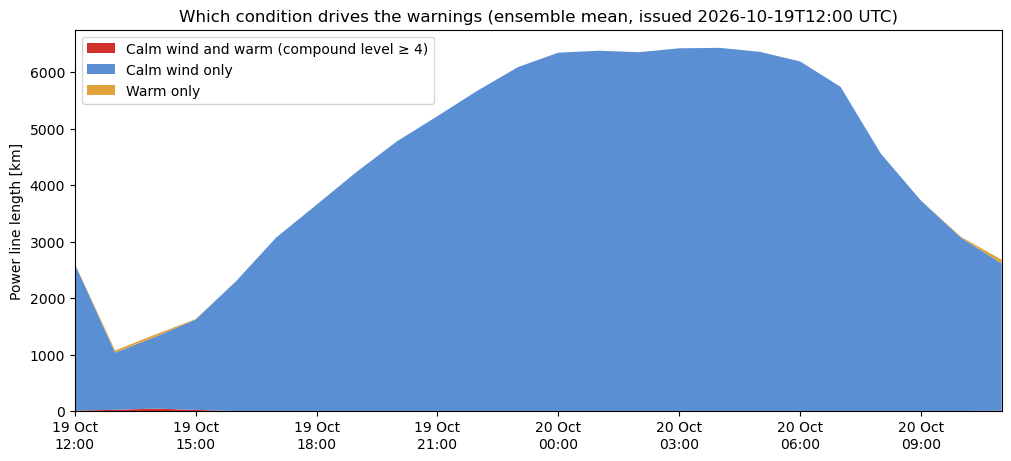

In [54]:
calm_wind = wind_mat >= 4
warm = temp_mat >= 2
km = ensemble_mean_km(imp_compound, {
    "Calm wind and warm (compound level ≥ 4)": calm_wind & warm,
    "Calm wind only": calm_wind & ~warm,
    "Warm only": warm & ~calm_wind,
})

fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
ax.stackplot(km.index, km.T.to_numpy(), labels=km.columns, colors=["#d0312d", "#5b8fd4", "#e0a33c"])
ax.set(ylabel="Power line length [km]", xlim=(km.index[0], km.index[-1]),
       title=f"Which condition drives the warnings (ensemble mean, issued {reference_time} UTC)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
ax.legend(loc="upper left")

### 7.4 Affected lines by voltage class

The OSM `voltage` tag (in V, several values separated by `;` for lines carrying several circuits) is grouped into classes using the highest value per line. The left panel shows the share of each class at compound level ≥ 4, the right panel the corresponding length.

Text(0.5, 0.98, 'Compound level ≥ 4 by voltage class (ensemble mean, issued 2026-10-19T12:00 UTC)')

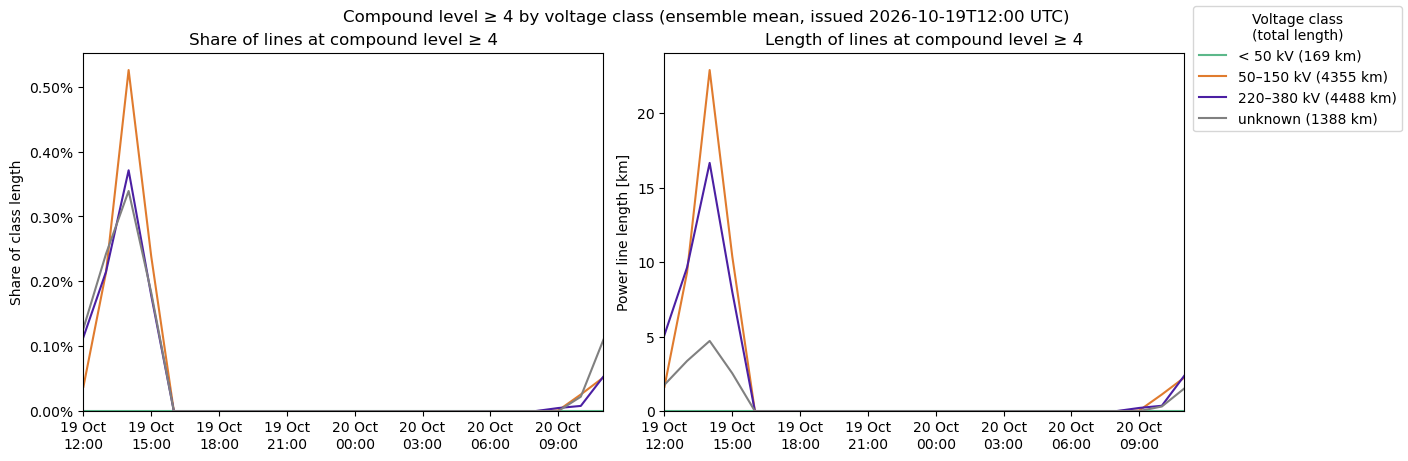

In [55]:
max_voltage_kv = pd.to_numeric(
    exp_lines.gdf.voltage.str.split(";").explode(), errors="coerce").groupby(level=0).max() / 1000
voltage_class = pd.cut(max_voltage_kv, [0, 50, 200, np.inf], right=False,
                       labels=["< 50 kV", "50–150 kV", "220–380 kV"])
voltage_class = voltage_class.cat.add_categories("unknown").fillna("unknown")
point_class = voltage_class.loc[line_id].to_numpy()

unfavorable = compound_mat >= 4
km = ensemble_mean_km(imp_compound, {
    name: unfavorable & (point_class == name) for name in voltage_class.cat.categories})
class_km = pd.Series(point_km).groupby(point_class).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
for name, color in zip(km.columns, ["#5cb88a", "#e07b2e", "#4b1fa3", "gray"]):
    if class_km.get(name, 0) == 0:
        continue
    label = f"{name} ({class_km[name]:.0f} km)"
    axes[0].plot(km.index, km[name] / class_km[name], color=color, label=label)
    axes[1].plot(km.index, km[name], color=color, label=label)
axes[0].yaxis.set_major_formatter(ticker.PercentFormatter(1))
axes[0].set(ylabel="Share of class length", title="Share of lines at compound level ≥ 4")
axes[1].set(ylabel="Power line length [km]", title="Length of lines at compound level ≥ 4")
for ax in axes:
    ax.set_xlim(km.index[0], km.index[-1])
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
fig.legend(*axes[0].get_legend_handles_labels(), title="Voltage class\n(total length)", loc="outside right upper")
fig.suptitle(f"Compound level ≥ 4 by voltage class (ensemble mean, issued {reference_time} UTC)")